# Unit 3: correlation and regression — reproducible evidence
Executed working copies of all four supplied exercises, followed by controlled experiments. Prepared with AI assistance; original supplied notebooks are unchanged. The first linear-regression cell corrects `stat` to `stats`. The missing module-4-machine-learning_correlation-and-regression-cars.csv is reconstructed using the three numeric columns of the 36-row replacement teaching dataset. Its fitted coefficients and predictions are checked against the supplied outputs. CO2 is retained in dataset units because the supplied file does not establish measurement metadata. All reported R² values are training scores unless labelled leave-one-out (LOOCV). Code cells were executed sequentially in a shared Python namespace; plots and printed results are embedded. Keep the accompanying module-4-machine-learning_correlation-and-regression-cars.csv in the same folder as this notebook when rerunning it.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy, sklearn
print('numpy',np.__version__,'pandas',pd.__version__,'scipy',scipy.__version__,'sklearn',sklearn.__version__)
results={}

numpy 2.4.4 pandas 3.0.2 scipy 1.17.1 sklearn 1.8.0


## Supplied exercise: Unit03 Ex1 covariance_pearson_correlation.ipynb

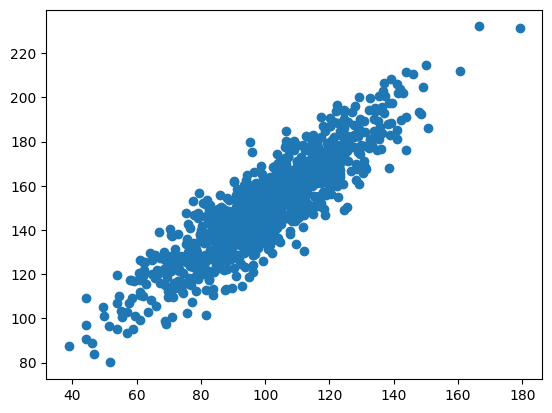

data1: mean=100.776 stdv=19.620
data2: mean=151.050 stdv=22.358
Covariance: 389.755
Pearsons correlation: 0.888


In [2]:

# calculate the Pearson's correlation between two variables
from numpy import mean
from numpy import std
from numpy import cov
from numpy.random import randn
from numpy.random import seed
from matplotlib import pyplot as plt
import seaborn as sns

from scipy.stats import pearsonr
# seed random number generator
seed(1)

# prepare data
data1 = 20 * randn(1000) + 100
data2 = data1 + (10 * randn(1000) + 50)

# calculate covariance matrix
covariance = cov(data1, data2)

# calculate Pearson's correlation
corr, _ = pearsonr(data1, data2)

# plot
plt.scatter(data1, data2)
plt.show()

# summarize
print('data1: mean=%.3f stdv=%.3f' % (mean(data1), std(data1)))
print('data2: mean=%.3f stdv=%.3f' % (mean(data2), std(data2)))
print('Covariance: %.3f' % covariance[0][1])
print('Pearsons correlation: %.3f' % corr)


## Supplied exercise: Unit03 Ex2 linear_regression.ipynb

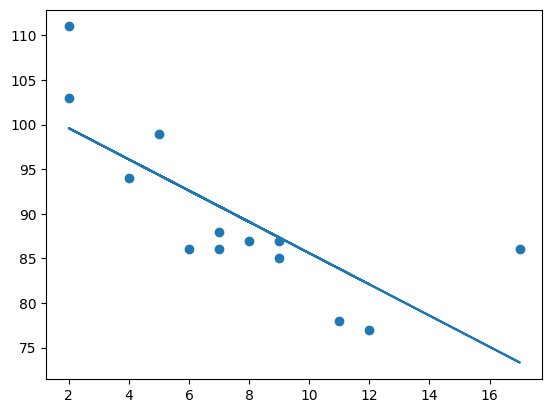

Pearsons correlation: -0.759


In [3]:
import matplotlib.pyplot as plt
from scipy import stats

#Create the arrays that represent the values of the x and y axis
x = [5,7,8,7,2,17,2,9,4,11,12,9,6]
y = [99,86,87,88,111,86,103,87,94,78,77,85,86]

#Execute a method that returns some important key values of Linear Regression
slope, intercept, r, p, std_err = stats.linregress(x, y)

# measure the correlation 
corr, _ = stats.pearsonr(x, y)
print('Pearsons correlation: %.3f' % corr)

#Create a function that uses the slope and intercept values to return a new value. 
#This new value represents where on the y-axis the corresponding x value will be placed
def myfunc(x):
  return slope * x + intercept

#Run each value of the x array through the function. This will result in a new array with new values for the y-axis
mymodel = list(map(myfunc, x))

#Draw the original scatter plot & the line of linear regression
plt.scatter(x, y)
plt.plot(x, mymodel)
plt.show()


In [4]:
from scipy import stats

x = [5,7,8,7,2,17,2,9,4,11,12,9,6]
y = [99,86,87,88,111,86,103,87,94,78,77,85,86]

slope, intercept, r, p, std_err = stats.linregress(x, y)

def myfunc(x):
  return intercept + slope * x 

speed = myfunc(10)

print(speed)

85.59308314937454


## Supplied exercise: Unit03 Ex3 multiple_linear_regression.ipynb

In [5]:
import pandas
from sklearn import linear_model

df = pandas.read_csv("module-4-machine-learning_correlation-and-regression-cars.csv")

X = df[['Weight', 'Volume']]
y = df['CO2']

regr = linear_model.LinearRegression()
regr.fit(X, y)

#predict the CO2 emission of a car where the weight is 2300kg, and the volume is 1300cm3:
predictedCO2 = regr.predict([[2300, 1300]])

print(predictedCO2)

[107.2087328]


In [6]:
print(regr.coef_)

[0.00755095 0.00780526]


In [7]:
predictedCO2 = regr.predict([[3300, 1300]])

print(predictedCO2)

[114.75968007]


## Supplied exercise: Unit03 Ex4 polynomial_regression.ipynb

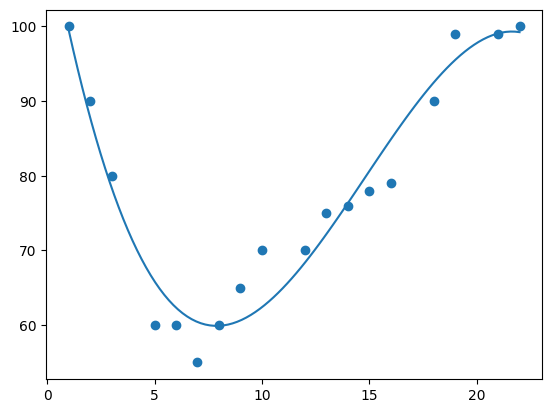

In [8]:
import numpy
import matplotlib.pyplot as plt

x = [1,2,3,5,6,7,8,9,10,12,13,14,15,16,18,19,21,22]
y = [100,90,80,60,60,55,60,65,70,70,75,76,78,79,90,99,99,100]

#NumPy has a method that lets us make a polynomial model
mymodel = numpy.poly1d(numpy.polyfit(x, y, 3))

#specify how the line will display, we start at position 1, and end at position 22
myline = numpy.linspace(1, 22, 100)

plt.scatter(x, y)
plt.plot(myline, mymodel(myline))
plt.show()

In [9]:
import numpy
from sklearn.metrics import r2_score

x = [1,2,3,5,6,7,8,9,10,12,13,14,15,16,18,19,21,22]
y = [100,90,80,60,60,55,60,65,70,70,75,76,78,79,90,99,99,100]

mymodel = numpy.poly1d(numpy.polyfit(x, y, 3))

print(r2_score(y, mymodel(x)))

0.9432150416451026


In [10]:
import numpy
from sklearn.metrics import r2_score

x = [1,2,3,5,6,7,8,9,10,12,13,14,15,16,18,19,21,22]
y = [100,90,80,60,60,55,60,65,70,70,75,76,78,79,90,99,99,100]

mymodel = numpy.poly1d(numpy.polyfit(x, y, 3))

speed = mymodel(17)
print(speed)

88.87331269698001


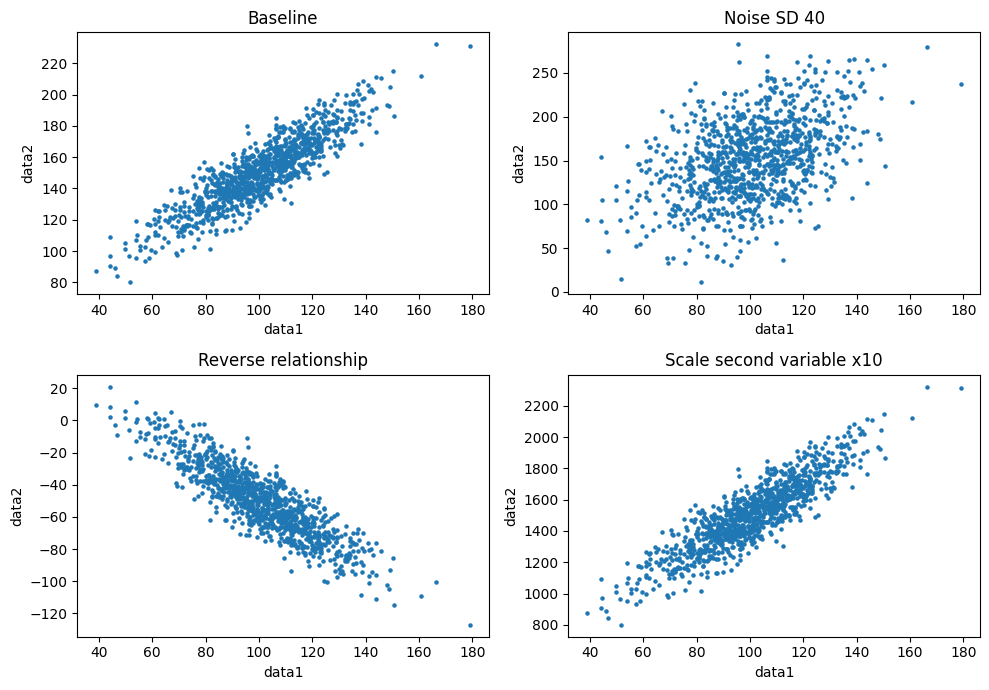

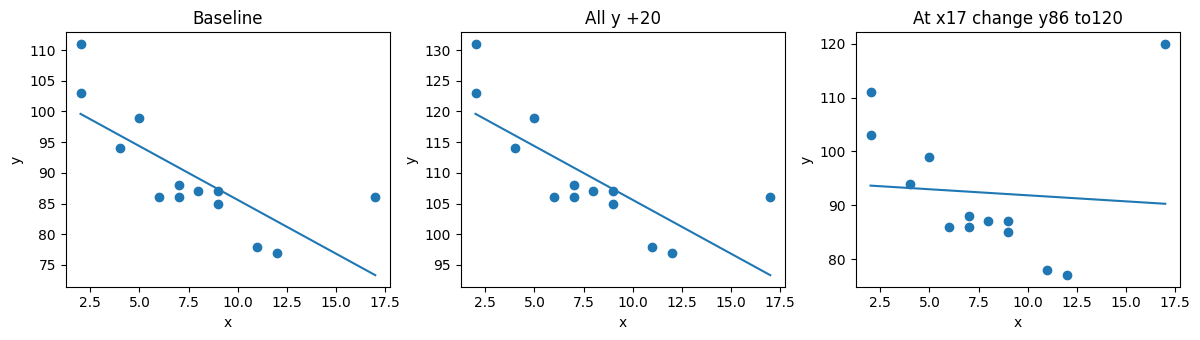

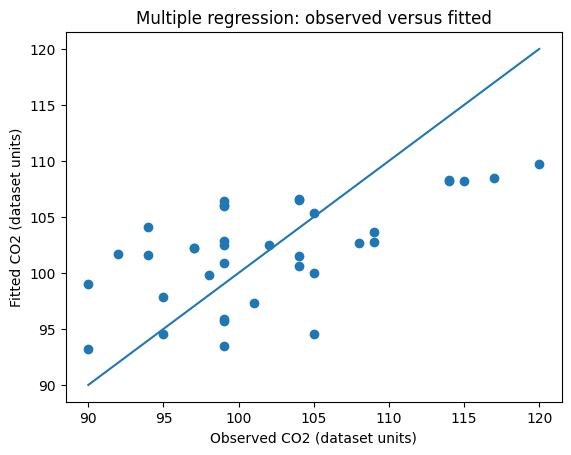

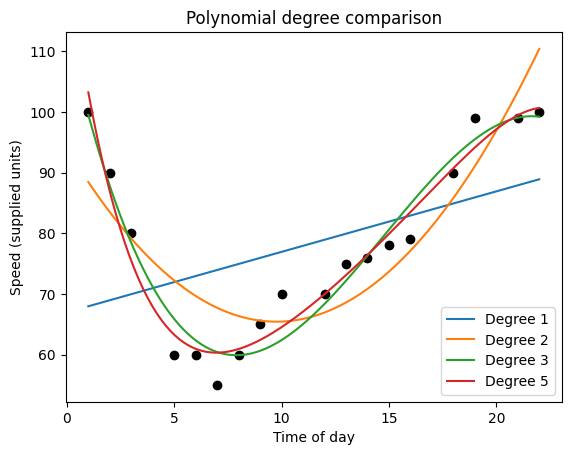

{
  "correlation": {
    "Baseline": {
      "covariance": 389.75456180261796,
      "r": 0.8876119085795309
    },
    "Noise SD 40": {
      "covariance": 403.01931532808345,
      "r": 0.4459057680555829
    },
    "Reverse relationship": {
      "covariance": -380.91139278564106,
      "r": -0.8832223448253473
    },
    "Scale second variable x10": {
      "covariance": 3897.54561802618,
      "r": 0.8876119085795311
    }
  },
  "linear": {
    "Baseline": {
      "slope": -1.7512877115526118,
      "intercept": 103.10596026490066,
      "r": -0.758591524376155,
      "r2": 0.5754611008553381,
      "prediction10": 85.59308314937454
    },
    "All y +20": {
      "slope": -1.7512877115526118,
      "intercept": 123.10596026490066,
      "r": -0.758591524376155,
      "r2": 0.5754611008553381,
      "prediction10": 105.59308314937454
    },
    "At x17 change y86 to120": {
      "slope": -0.22516556291390738,
      "intercept": 94.09933774834437,
      "r": -0.07420462519732685,


In [11]:
from scipy.stats import pearsonr, linregress
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
np.random.seed(1)
a=20*np.random.randn(1000)+100
z=np.random.randn(1000)
b=a+10*z+50
cases={'Baseline':(a,b),'Noise SD 40':(a,a+40*z+50),'Reverse relationship':(a,-a+10*z+50),'Scale second variable x10':(a,10*b)}
results['correlation']={}
fig,axes=plt.subplots(2,2,figsize=(10,7))
for ax,(name,(u,v)) in zip(axes.flat,cases.items()):
 results['correlation'][name]={'covariance':float(np.cov(u,v)[0,1]),'r':float(pearsonr(u,v).statistic)}
 ax.scatter(u,v,s=5); ax.set(title=name,xlabel='data1',ylabel='data2')
plt.tight_layout(); plt.show()
x=np.array([5,7,8,7,2,17,2,9,4,11,12,9,6])
y=np.array([99,86,87,88,111,86,103,87,94,78,77,85,86])
changed=y.copy(); changed[5]=120
results['linear']={}
fig,axes=plt.subplots(1,3,figsize=(12,3.5))
for ax,(name,v) in zip(axes,{'Baseline':y,'All y +20':y+20,'At x17 change y86 to120':changed}.items()):
 fit=linregress(x,v); pred=fit.intercept+fit.slope*x
 results['linear'][name]={'slope':float(fit.slope),'intercept':float(fit.intercept),'r':float(fit.rvalue),'r2':float(r2_score(v,pred)),'prediction10':float(fit.intercept+10*fit.slope)}
 ax.scatter(x,v); grid=np.array([2,17]); ax.plot(grid,fit.intercept+fit.slope*grid); ax.set(title=name,xlabel='x',ylabel='y')
plt.tight_layout(); plt.show()
df=pd.read_csv('module-4-machine-learning_correlation-and-regression-cars.csv'); X=df[['Weight','Volume']]; y=df.CO2
model=LinearRegression().fit(X,y)
assert np.allclose(model.coef_,[0.00755095,0.00780526],atol=1e-8)
assert np.isclose(model.predict(pd.DataFrame([[2300,1300]],columns=X.columns))[0],107.2087328)
results['multiple']={'n':len(df),'range':{c:[float(X[c].min()),float(X[c].max())] for c in X},'intercept':float(model.intercept_),'coefficients':model.coef_.tolist(),'r2':float(model.score(X,y)),'predictor_r':float(X.corr().iloc[0,1])}
for name,cols in [('Weight only',['Weight']),('Volume only',['Volume']),('Both',['Weight','Volume'])]:
 m=LinearRegression().fit(X[cols],y)
 cv=cross_val_predict(LinearRegression(),X[cols],y,cv=LeaveOneOut())
 results['multiple'][name]={'r2':float(m.score(X[cols],y)),'loocv_rmse':float(np.sqrt(mean_squared_error(y,cv)))}
results['multiple']['predictions']={str(row):float(model.predict(pd.DataFrame([row],columns=X.columns))[0]) for row in [[2300,1300],[3300,1300],[2300,2300]]}
changed=y.copy(); changed.iloc[-1]+=30
altered=LinearRegression().fit(X,changed)
results['multiple']['last CO2 +30']={'coefficients':altered.coef_.tolist(),'r2':float(altered.score(X,changed)),'prediction':float(altered.predict(pd.DataFrame([[2300,1300]],columns=X.columns))[0])}
fig,ax=plt.subplots(); ax.scatter(y,model.predict(X)); ax.plot([90,120],[90,120]); ax.set(xlabel='Observed CO2 (dataset units)',ylabel='Fitted CO2 (dataset units)',title='Multiple regression: observed versus fitted'); plt.show()
x=np.array([1,2,3,5,6,7,8,9,10,12,13,14,15,16,18,19,21,22])
y=np.array([100,90,80,60,60,55,60,65,70,70,75,76,78,79,90,99,99,100])
results['polynomial']={}
fig,ax=plt.subplots(); ax.scatter(x,y,color='black'); grid=np.linspace(1,22,200)
for degree in [1,2,3,5]:
 m=np.poly1d(np.polyfit(x,y,degree))
 cv=cross_val_predict(make_pipeline(PolynomialFeatures(degree),LinearRegression()),x.reshape(-1,1),y,cv=LeaveOneOut())
 results['polynomial'][str(degree)]={'r2':float(r2_score(y,m(x))),'prediction17':float(m(17)),'prediction30':float(m(30)),'loocv_rmse':float(np.sqrt(mean_squared_error(y,cv)))}
 ax.plot(grid,m(grid),label='Degree '+str(degree))
ax.legend(); ax.set(xlabel='Time of day',ylabel='Speed (supplied units)',title='Polynomial degree comparison'); plt.show()
changed=y.copy(); changed[-1]=140
m=np.poly1d(np.polyfit(x,changed,3))
results['polynomial']['last speed100 to140']={'r2':float(r2_score(changed,m(x))),'prediction17':float(m(17)),'prediction30':float(m(30))}
import json
print(json.dumps(results,indent=2))
from pathlib import Path
Path('module-4-machine-learning_correlation-and-regression-results.json').write_text(json.dumps(results,indent=2))
